In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error as mse, mean_absolute_error as mae, root_mean_squared_error as rmse
from itertools import product
import lightgbm as lgb

cwd = Path.cwd()
root = cwd.parent

data = pd.read_csv(str(cwd / 'processed_added_features.csv'))
numeric = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
categorical = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP',
                          'GLSSPC', 'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']
engineered = ['workers_per_1000_sqft', 'weekly_floor_area_hours', 'heated_floor_area', 
              'cooled_floor_area', 'heating_area_degree_days', 'cooling_area_degree_days',
              'NFLOOR_CEILING_HEIGHT', 'HDD65_CDD65', 'COOLP_HEATP', 'SQFT_WKHRS']
data = data.drop(columns='MAINHT__missing') # duplicate column
data = data.rename(columns={'Unnamed: 0':'ROW_ID'}) # default index
data = data.set_index('ROW_ID')

processed = data.copy(True)

In [3]:
# Condensing dummies. Lightgbm handles categoricals natively.
for cat in categorical:
    cols = None
    if cat == 'NFLOOR':
        suffixes = ['__code','__withheld','__missing','__15','__10_to_14']
        cols = [c for c in data.columns if cat in c and any(s in c for s in suffixes)]
    elif cat == 'PUBCLIM':
        suffixes = ['__code','__withheld','__missing']
        cols = [c for c in data.columns if cat in c and any(s in c for s in suffixes)]
    else:
        suffixes = ['__code','__missing']
        cols = [c for c in data.columns if cat in c and any(s in c for s in suffixes)]
    processed[cat] = pd.from_dummies(data[cols], sep='__', default_category='UNKNOWN')[cat].astype('category')

processed['CENDIV_PUBCLIM'] = pd.from_dummies(data[[c for c in data.columns if 'CENDIV_PUBCLIM' in c]], sep='_', default_category='UNKNOWN').astype('category')

In [4]:
# features, target, train/val/test splits
X = processed[numeric + categorical + engineered]
y = processed[['MFBTU']]

X_train = X[data['split']=='train']
y_train = y[data['split']=='train']
X_val = X[data['split']=='validation']
y_val = y[data['split']=='validation']
X_test = X[data['split']=='test']
y_test = y[data['split']=='test']

In [5]:
# Initial, unoptimized model
model = lgb.LGBMRegressor()
model.fit(X_train, y_train, eval_X=X_val, eval_y=y_val)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000986 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3657
[LightGBM] [Info] Number of data points in the train set: 4449, number of used features: 33
[LightGBM] [Info] Start training from score 15868331.388851


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [6]:
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

print("Training RMSE: ", np.sqrt(mse(train_pred, y_train)))
print("Training R squared: ", r2_score(y_train, train_pred))
print("Validation RMSE: ", np.sqrt(mse(val_pred, y_val)))
print("Validation R squared: ", r2_score(y_val, val_pred))

Training RMSE:  9903599.476392375
Training R squared:  0.9329870704459152
Validation RMSE:  13620030.372420581
Validation R squared:  0.8606060721830284


In [ ]:
# hyperparameter optimization, simple grid search
seed = 1

param_grid = {
    'num_leaves': [3, 5, 7, 15, 31, 63, 97],
    'min_child_samples': [10, 20, 40, 80],
    'feature_fraction': [.7, .85, 1.0],
    'lambda_l2': [0, 0.5, 1],
    'learning_rate': [0.15, 0.1, 0.05]
}

base_params = {
    'metric': 'l2',
    'objective': 'regression',
    'learning_rate': 0.1,
    'seed': seed,
    'deterministic': True,
    'force_col_wise': True,
    'verbose': -1
}

keys = list(param_grid)
configs = [{**base_params, **dict(zip(keys, vals))} for vals in product(*param_grid.values())]

In [8]:
def score(true:np.ndarray, pred:np.ndarray):
    return {
        'rmse': rmse(true, pred),
        'mae': mae(true, pred),
        'r2_score': r2_score(true, pred)
    }

In [9]:
def search(configs: list[dict], 
           x_train:pd.DataFrame, 
           y_train:pd.DataFrame,
           x_val:pd.DataFrame,
           y_val:pd.DataFrame
           ):
    summary = []
    best = 0
    dtrain = lgb.Dataset(x_train, y_train)
    dval = lgb.Dataset(x_val, y_val)
    for cid, params in enumerate(configs):
        s = lgb.train(
            train_set=dtrain, 
            params=params, 
            valid_sets=[dval],
            num_boost_round=200,
            callbacks=([lgb.early_stopping(stopping_rounds=100, verbose=False)])
            )            
        pred = s.predict(X_val)
        summary.append(score(y_val, pred))
        if summary[cid]['rmse'] < summary[best]['rmse']:
            best = cid
    return summary, best

In [10]:
# scores, best = search(configs, X_train, y_train, X_val, y_val)

In [11]:
# # best hyperparameter configuration
# min_s = 0
# for i, s in enumerate(scores):
#     if s['rmse'] < scores[min_s]['rmse']:
#         min_s = i
# scores[min_s]
# configs[min_s]

1st optimized config:

- Learning rate = 0.1
- Number of leaves = 5
- Min child samples = 20
- Feature fraction = 100%
- L2 Lambda = 1

In [13]:
# optimized config:
best_config = {
    'metric': 'l2',
    'objective': 'regression',
    'learning_rate': 0.1,
    'seed': 1,
    'deterministic': True,
    'force_col_wise': True,
    'verbose': -1,
    'num_leaves': 5,
    'min_child_samples': 20,
    'feature_fraction': 1.0,
    'lambda_l2': 1}

# Final refit on best config
train = lgb.Dataset(X_train, y_train)
model_opt = lgb.train(train_set=train, params=best_config)
opt_pred_train = model_opt.predict(X_train)
opt_pred_val = model_opt.predict(X_val)

print(f"""Train scores: 
{score(y_train, opt_pred_train)}

Val scores:
{score(y_val, opt_pred_val)}
""")

Train scores: 
{'rmse': 13699691.157834435, 'mae': 5107553.307550648, 'r2_score': 0.8717687071317581}

Val scores:
{'rmse': 12934291.36060748, 'mae': 5144882.296759719, 'r2_score': 0.8742890862605399}



<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

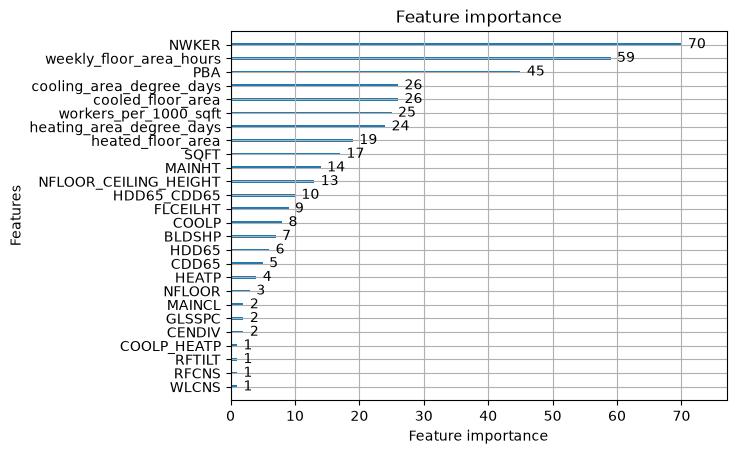

In [18]:
lgb.plot_importance(model_opt, importance_type='split', precision=2)